# Influence Score Correlation Analysis

This notebook analyzes the correlation between different influence score types and the performance metrics from the golden layer analysis.

## Objectives:
1. Load influence scores from TracInInf files (one at a time for memory efficiency)
2. Compute correlation with performance metrics (for proxy, test, and all samples)
3. Identify best layers selected by each influence score type (min and max)
4. Present results in comprehensive tables

In [39]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import warnings
import gc
warnings.filterwarnings('ignore')

# Import the golden layer API
from golden_layer_api import GoldenLayerAnalyzer

# Naming conversion function
def convert_influence_name(internal_name):
    """
    Convert internal influence type names to readable format.
    
    Mapping:
    - OverallNew -> Overall_new
    - OverallOrig/OverallHat -> overall_hat
    - OverallTruth -> overall_truth
    - THAT -> y_hat
    - TNew -> y_new
    - TTruth -> y_truth
    - Query -> Query
    - CausalTraceProba.last -> CMA (last subject token)
    - HiddenStates -> HS
    - l2normSpecific -> L2-Norm
    - specific -> TracIn
    """
    # Handle CausalTraceProba
    if 'CausalTraceProba' in internal_name:
        return 'CMA (last subject token)'
    
    # Handle HiddenStates
    if internal_name.startswith('HiddenStates.'):
        parts = internal_name.split('.')
        if len(parts) == 3:
            hs_type = parts[1]  # HSMlp, HSAttn, etc.
            target = parts[2]
            
            # Map the target
            target_map = {
                'OverallNew': 'overall_new',
                'OverallOrig': 'overall_hat',
                'OverallHat': 'overall_hat'
            }
            mapped_target = target_map.get(target, target)
            
            # Simplify HS type
            hs_map = {
                'HSMlp': 'HS-MLP',
                'HSAttn': 'HS-Attn',
                'HSHs': 'HS-HS',
                'HSDiffMlp': 'HS-Diff-MLP',
                'HSDiffAttn': 'HS-Diff-Attn',
                'HSDiffHs': 'HS-Diff-HS'
            }
            hs_str = hs_map.get(hs_type, hs_type)
            
            return f'{hs_str} ({mapped_target})'
    
    # Handle l2normSpecific and specific
    prefix = ''
    if internal_name.startswith('l2normSpecific.'):
        prefix = 'L2-Norm'
        remainder = internal_name[15:]  # Remove 'l2normSpecific.'
    elif internal_name.startswith('specific.'):
        prefix = 'TracIn'
        remainder = internal_name[9:]  # Remove 'specific.'
    else:
        return internal_name
    
    # Split by camelCase
    parts = []
    current = ''
    for char in remainder:
        if char.isupper() and current:
            parts.append(current)
            current = char
        else:
            current += char
    if current:
        parts.append(current)
    
    # Map each part
    part_map = {
        'Overall': 'overall',
        'OverallNew': 'overall_new',
        'OverallHat': 'overall_hat',
        'OverallOrig': 'overall_hat',
        'OverallTruth': 'overall_truth',
        'THAT': 'y_hat',
        'TNew': 'y_new',
        'TTruth': 'y_truth',
        'Query': 'Query'
    }
    
    mapped_parts = [part_map.get(part, part.lower()) for part in parts]
    
    # Format the result
    if len(mapped_parts) == 1:
        return f'{prefix} ({mapped_parts[0]})'
    else:
        return f'{prefix} ({mapped_parts[0]} & {mapped_parts[1]})'

## 1. Load Performance Metrics from Golden Layer Analysis

In [40]:
# Load the golden layer analysis results
print("Loading golden layer analysis results...")
analyzer = GoldenLayerAnalyzer(data_dir='../allLayerPerformance')
(analyzer
    .load_data(verbose=False)
    .compute_overall_metric(verbose=False)
    .split_dataset(proxy_size=100, random_seed=42, verbose=True)
    .compute_proxy_test_means(verbose=False)
    .analyze(verbose=False))

print("\nGolden layer analysis loaded successfully!")
print(f"Proxy indices: {len(analyzer.proxy_indices)} samples")
print(f"Test indices: {len(analyzer.test_indices)} samples")

Loading golden layer analysis results...

Dataset split:
  Total samples: 1031
  Proxy set: 100 samples
  Test set: 931 samples

Golden layer analysis loaded successfully!
Proxy indices: 100 samples
Test indices: 931 samples


## 2. Define Influence Score Types

In [41]:
# Directory containing influence scores
influence_dir = Path('../../lga_scores//modelName-meta-llama')

# Find all available influence score types for gpt2-xl with 1037 samples
influence_files = list(influence_dir.glob('Llama-2-7b-hf_dataset-OrigCounterfact_*_nsamples-1031.pt'))

# Extract overall types from filenames
influence_types = []
for f in influence_files:
    fname = f.name
    # Extract overall-<type> part
    if 'overall-' in fname:
        overall_part = fname.split('overall-')[1].split('_layers')[0]

            # ---- EXCLUSIONS ----
        if overall_part.startswith('HiddenStates') and overall_part.endswith('test'):
            continue

        influence_types.append(overall_part)

influence_types = sorted(set(influence_types))

print(f"Found {len(influence_types)} influence score types:")
for i, inf_type in enumerate(influence_types, 1):
    print(f"  {i:2d}. {inf_type}")

Found 8 influence score types:
   1. CausalTraceProba.last
   2. l2normSpecific.OverallHat
   3. l2normSpecific.OverallTruth
   4. l2normSpecific.THAT
   5. specific.OverallNewOverallHat
   6. specific.OverallTruthOverallNew
   7. specific.QueryOverallTruth
   8. specific.TTruthTNew


## 3. Load Influence Scores Function (Memory Efficient)

In [42]:
def load_influence_scores(overall_type, influence_dir):
    """
    Load influence scores for a given overall type.
    Handles:
    - Both norm-True and norm-False variants (they should be the same)
    - HiddenStates files with 49 layers (strips first embedding layer)
    - CausalTraceProba.last format (list of tensors)
    - Converts CausalTraceProba scores to float32 if they are bfloat16
    Args:
        overall_type: The overall score type (e.g., 'specific.OverallNewTHAT')
        influence_dir: Directory containing influence files
    Returns:
        torch.Tensor of shape (n_samples, n_layers) or None if not found/error
    """
    # Try norm-True first
    pattern = f'Llama-2-7b-hf_dataset-OrigCounterfact_*_overall-{overall_type}_layers-32__nsamples-1031.pt'
    files = list(influence_dir.glob(pattern))
    # If not found, try norm-False
    if not files:
        pattern = f'Llama-2-7b-hf_dataset-OrigCounterfact_*_norm-False_overall-{overall_type}_layers-32__nsamples-1031.pt'
        files = list(influence_dir.glob(pattern))
    if not files:
        return None, f"No file found for {overall_type}"
    try:
        # Load the first matching file
        data = torch.load(files[0], map_location='cpu')
        scores = None
        if isinstance(data, torch.Tensor):
            scores = data
        elif isinstance(data, list):
            # CausalTraceProba.last returns list of tensors
            if len(data) > 0:
                if isinstance(data[0], torch.Tensor):
                    if data[0].dim() == 1:
                        scores = torch.stack(data)
                    elif data[0].dim() == 2:
                        last_token_scores = [sample_scores[-1] for sample_scores in data]
                        scores = torch.stack(last_token_scores)
        elif isinstance(data, dict):
            for key in ['scores', 'influence', 'data', 'influences']:
                if key in data:
                    if isinstance(data[key], torch.Tensor):
                        scores = data[key]
                        break
                    elif isinstance(data[key], list):
                        if len(data[key]) > 0 and isinstance(data[key][0], torch.Tensor):
                            if data[key][0].dim() == 1:
                                scores = torch.stack(data[key])
                            elif data[key][0].dim() == 2:
                                last_token_scores = [s[-1] for s in data[key]]
                                scores = torch.stack(last_token_scores)
                        break
            if scores is None:
                for v in data.values():
                    if isinstance(v, torch.Tensor):
                        scores = v
                        break
        if scores is None:
            return None, f"Could not extract tensor from {type(data)}"
        # Convert bfloat16 to float32 for CausalTraceProba
        if 'CausalTraceProba' in overall_type and scores.dtype == torch.bfloat16:
            scores = scores.to(torch.float32)
        # Handle HiddenStates files with 49 layers (first is embedding)
        if scores.shape == (1031, 49):
            if 'HiddenStates' in overall_type:
                scores = scores[:, 1:]
                print(f"  Note: Stripped embedding layer from {overall_type}, shape now {scores.shape}")
            else:
                return None, f"Unexpected 49 layers for non-HiddenStates type: {overall_type}"
        if scores.shape != (1031, 32):
            return None, f"Unexpected shape {scores.shape}, expected (1031, 48)"
        return scores, None
    except Exception as e:
        return None, f"Error loading: {str(e)}"

# Test loading one file
print("Testing influence score loading...")
test_type = influence_types[0]
test_scores, error = load_influence_scores(test_type, influence_dir)
if test_scores is not None:
    print(f"✓ Successfully loaded {test_type}: shape {test_scores.shape}")
else:
    print(f"✗ Failed to load {test_type}: {error}")


Testing influence score loading...
✓ Successfully loaded CausalTraceProba.last: shape torch.Size([1031, 32])


## 4. Compute Correlations with Performance Metrics

In [43]:
def compute_correlation(influence_scores, performance_means):
    """
    Compute correlation between influence scores and performance metrics.
    
    Args:
        influence_scores: Tensor of shape (n_samples, n_layers)
        performance_means: Tensor of shape (n_layers,) - mean performance per layer
    
    Returns:
        Pearson correlation coefficient
    """
    # Average influence scores across samples to get per-layer scores
    influence_means = torch.nanmean(influence_scores, dim=0).numpy()
    performance_means_np = performance_means.numpy()
    
    # Remove NaN values
    valid_mask = ~(np.isnan(influence_means) | np.isnan(performance_means_np))
    
    if valid_mask.sum() < 2:
        return np.nan
    
    # Compute Pearson correlation
    corr, _ = stats.pearsonr(influence_means[valid_mask], performance_means_np[valid_mask])
    
    return corr


# Compute correlations for all influence types (one at a time)
print("Computing correlations with performance metrics...\n")
print("Progress:")

correlation_results = []
failed_types = []

for idx, inf_type in enumerate(influence_types, 1):
    print(f"  [{idx:2d}/{len(influence_types)}] Processing {inf_type[:50]}...", end=' ')
    
    # Load influence scores
    scores, error = load_influence_scores(inf_type, influence_dir)
    
    if scores is None:
        print(f"FAILED: {error}")
        failed_types.append({'Influence Type': inf_type, 'Error': error})
        continue
    
    result = {'Influence Type': inf_type}
    
    # Compute correlations for each performance metric
    for metric_key, metric_name in analyzer.metrics_info:
        # All samples
        all_scores = scores
        all_means = torch.nanmean(analyzer.results[metric_key], dim=0)
        corr_all = compute_correlation(all_scores, all_means)
        result[f'{metric_name} (All)'] = corr_all
        
        # Proxy samples
        proxy_scores = scores[analyzer.proxy_indices, :]
        corr_proxy = compute_correlation(proxy_scores, analyzer.proxy_means[metric_key])
        result[f'{metric_name} (Proxy)'] = corr_proxy
        
        # Test samples
        test_scores = scores[analyzer.test_indices, :]
        corr_test = compute_correlation(test_scores, analyzer.test_means[metric_key])
        result[f'{metric_name} (Test)'] = corr_test
    
    correlation_results.append(result)
    print("OK")
    
    # Free memory
    del scores
    gc.collect()

print(f"\n✓ Computed correlations for {len(correlation_results)} influence types.")
if failed_types:
    print(f"✗ Failed to load {len(failed_types)} influence types.")

Computing correlations with performance metrics...

Progress:
  [ 1/8] Processing CausalTraceProba.last... OK
  [ 2/8] Processing l2normSpecific.OverallHat... OK
  [ 3/8] Processing l2normSpecific.OverallTruth... OK
  [ 4/8] Processing l2normSpecific.THAT... OK
  [ 5/8] Processing specific.OverallNewOverallHat... OK
  [ 6/8] Processing specific.OverallTruthOverallNew... OK
  [ 7/8] Processing specific.QueryOverallTruth... OK
  [ 8/8] Processing specific.TTruthTNew... OK

✓ Computed correlations for 8 influence types.


## 5. Display Correlation Results Table

In [44]:
# Create DataFrame
df_correlations = pd.DataFrame(correlation_results)

# Display full table
print("="*150)
print("CORRELATION BETWEEN INFLUENCE SCORES AND PERFORMANCE METRICS")
print("="*150)
print("\nNote: Correlations computed using layer-wise means")
print("Positive correlation: Higher influence score → Better performance")
print("Negative correlation: Lower influence score → Better performance\n")

# Show with better formatting
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.precision', 4)
print(df_correlations.to_string(index=False))

# Show failed types if any
if failed_types:
    print("\n" + "="*150)
    print("FAILED TO LOAD:")
    print("="*150)
    df_failed = pd.DataFrame(failed_types)
    print(df_failed.to_string(index=False))

CORRELATION BETWEEN INFLUENCE SCORES AND PERFORMANCE METRICS

Note: Correlations computed using layer-wise means
Positive correlation: Higher influence score → Better performance
Negative correlation: Lower influence score → Better performance

                 Influence Type  Rewrite Accuracy (All)  Rewrite Accuracy (Proxy)  Rewrite Accuracy (Test)  Rephrase Accuracy (All)  Rephrase Accuracy (Proxy)  Rephrase Accuracy (Test)  Locality (All)  Locality (Proxy)  Locality (Test)  Portability (All)  Portability (Proxy)  Portability (Test)  Overall (All)  Overall (Proxy)  Overall (Test)
          CausalTraceProba.last                  0.1604                    0.1485                   0.1618                   0.5364                     0.6110                    0.5294          0.1760            0.0955           0.1852             0.5214               0.4420              0.5285         0.3569           0.3428          0.3588
      l2normSpecific.OverallHat                  0.2349            

## 6. Find Best Layers Selected by Each Influence Type

In [45]:
def find_best_layers(
    influence_scores: torch.Tensor,
    influence_type: str,
    outlier_method: str = "iqr",
    iqr_multiplier: float = 1,
    verbose: bool = True,
    mode = "min"
):
    """
    Find best layer(s) while reporting removed layers.

    Returns:
        best_layers: List[int]
        diagnostics: dict
    """

    diagnostics = {
        "invalid_layers": [],
        "outlier_layers": [],
        "kept_layers": [],
        "outlier_bounds": None,
        "best_value": None,
    }

    # 1. Mean across samples
    layer_means = torch.nanmean(influence_scores, dim=0).cpu().numpy()
    # print("layer Means: ", layer_means)

    # 2. Remove invalid values
    valid_mask = np.isfinite(layer_means)
    invalid_indices = np.where(~valid_mask)[0].tolist()
    diagnostics["invalid_layers"] = invalid_indices

    if verbose and invalid_indices:
        print(f"Removed invalid layers (NaN/±inf): {invalid_indices}")

    valid_indices = np.where(valid_mask)[0]
    valid_means = layer_means[valid_mask]

    if valid_means.size == 0:
        raise ValueError("All layers invalid after NaN/inf removal.")

    # 3. Outlier removal
    if outlier_method == "iqr" and valid_means.size > 2 and ("CausalTraceProba" not in influence_type):
        q1 = np.percentile(valid_means, 25)
        q3 = np.percentile(valid_means, 75)
        iqr = q3 - q1

        lower = q1 - iqr_multiplier * iqr
        upper = q3 + iqr_multiplier * iqr
        diagnostics["outlier_bounds"] = (lower, upper)

        inlier_mask = (valid_means >= lower) & (valid_means <= upper)

        outlier_indices = valid_indices[~inlier_mask].tolist()
        diagnostics["outlier_layers"] = outlier_indices

        if verbose and outlier_indices:
            print(
                f"Removed outlier layers (IQR): {outlier_indices} "
                f"[bounds: {lower:.4g}, {upper:.4g}]"
            )

        valid_indices = valid_indices[inlier_mask]
        valid_means = valid_means[inlier_mask]

        if valid_means.size == 0:
            raise ValueError("All layers removed as outliers.")

    diagnostics["kept_layers"] = valid_indices.tolist()

    # 4. Select best
    if ("CausalTraceProba" in influence_type) or (mode =="max"):
        best_value = np.max(valid_means)
    else:
        best_value = np.min(valid_means)

    diagnostics["best_value"] = float(best_value)

    best_layers = valid_indices[valid_means == best_value].tolist()

    if verbose:
        print(f"Selected best layers: {best_layers} (value={best_value:.4g})")

    return best_layers


# Find best layers for each influence type (one at a time)
print("Finding best layers selected by each influence type...\n")
print("Progress:")

best_layer_results = []

for idx, inf_type in enumerate(influence_types, 1):
    print(f"  [{idx:2d}/{len(influence_types)}] Processing {inf_type[:50]}...", end=' ')
    
    # Load influence scores
    scores, error = load_influence_scores(inf_type, influence_dir)
    
    if scores is None:
        print("SKIP")
        continue
    
    result = {'Influence Type': inf_type}
    
    # All samples
    result['Max Layer (All)'] = str(find_best_layers(scores, inf_type, mode='max'))
    result['Min Layer (All)'] = str(find_best_layers(scores, inf_type, mode='min'))
    
    # Proxy samples
    proxy_scores = scores[analyzer.proxy_indices, :]
    result['Max Layer (Proxy)'] = str(find_best_layers(proxy_scores, inf_type, mode='max'))
    result['Min Layer (Proxy)'] = str(find_best_layers(proxy_scores, inf_type, mode='min'))
    
    # Test samples
    test_scores = scores[analyzer.test_indices, :]
    result['Max Layer (Test)'] = str(find_best_layers(test_scores, inf_type, mode='max'))
    result['Min Layer (Test)'] = str(find_best_layers(test_scores, inf_type, mode='min'))
    
    best_layer_results.append(result)
    print("OK")
    
    # Free memory
    del scores
    gc.collect()

print(f"\n✓ Found best layers for {len(best_layer_results)} influence types.")

Finding best layers selected by each influence type...

Progress:
  [ 1/8] Processing CausalTraceProba.last... Selected best layers: [6] (value=0.2708)
Selected best layers: [6] (value=0.2708)
Selected best layers: [7, 9] (value=0.244)
Selected best layers: [7, 9] (value=0.244)
Selected best layers: [6] (value=0.2739)
Selected best layers: [6] (value=0.2739)
OK
  [ 2/8] Processing l2normSpecific.OverallHat... Removed outlier layers (IQR): [1, 2, 3, 4, 30, 31] [bounds: -163.9, 23.37]
Selected best layers: [12] (value=-21.38)
Removed outlier layers (IQR): [1, 2, 3, 4, 30, 31] [bounds: -163.9, 23.37]
Selected best layers: [16] (value=-146.3)
Removed outlier layers (IQR): [1, 2, 3, 4, 16, 30, 31] [bounds: -178.4, 18.99]
Selected best layers: [12] (value=-25.22)
Removed outlier layers (IQR): [1, 2, 3, 4, 16, 30, 31] [bounds: -178.4, 18.99]
Selected best layers: [19] (value=-138)
Removed outlier layers (IQR): [1, 2, 3, 4, 30, 31] [bounds: -165.3, 25.28]
Selected best layers: [12] (value=-20.

## 7. Display Best Layer Results Table

In [46]:
# Create DataFrame
df_best_layers = pd.DataFrame(best_layer_results)

# Display full table
print("="*150)
print("BEST LAYERS SELECTED BY INFLUENCE SCORES")
print("="*150)
print("\nNote: Best layers determined by averaging influence scores across samples")
print("Max Layer: Layer with highest average influence score")
print("Min Layer: Layer with lowest average influence score\n")

pd.set_option('display.max_rows', None)
print(df_best_layers.to_string(index=False))

BEST LAYERS SELECTED BY INFLUENCE SCORES

Note: Best layers determined by averaging influence scores across samples
Max Layer: Layer with highest average influence score
Min Layer: Layer with lowest average influence score

                 Influence Type Max Layer (All) Min Layer (All) Max Layer (Proxy) Min Layer (Proxy) Max Layer (Test) Min Layer (Test)
          CausalTraceProba.last             [6]             [6]            [7, 9]            [7, 9]              [6]              [6]
      l2normSpecific.OverallHat            [12]            [16]              [12]              [19]             [12]             [16]
    l2normSpecific.OverallTruth            [12]            [16]              [12]              [16]             [12]             [16]
            l2normSpecific.THAT            [28]             [6]              [26]               [3]             [28]              [6]
  specific.OverallNewOverallHat            [12]             [4]              [12]               [3]       

## 8. Compare with Golden Layer

In [47]:
# Get golden layer from analyzer
golden_layer_proxy = analyzer.best_layers_comparison['post_overall']['proxy_best_layers']
golden_layer_test = analyzer.best_layers_comparison['post_overall']['test_best_layers']

print("="*70)
print("GOLDEN LAYER COMPARISON")
print("="*70)
print(f"\nGolden Layer (Proxy): {golden_layer_proxy}")
print(f"Golden Layer (Test): {golden_layer_test}")

# Find influence types that select the golden layer
print("\n\nInfluence types that select the golden layer:")
print("-" * 70)

matches = []
for result in best_layer_results:
    inf_type = result['Influence Type']
    
    # Check if any max/min layer matches golden layer
    for layer_col in ['Max Layer (All)', 'Min Layer (All)', 'Max Layer (Proxy)', 
                      'Min Layer (Proxy)', 'Max Layer (Test)', 'Min Layer (Test)']:
        layers_str = result[layer_col]
        layers = eval(layers_str)  # Convert string back to list
        
        # Check overlap with golden layers
        overlap_proxy = set(layers) & set(golden_layer_proxy)
        overlap_test = set(layers) & set(golden_layer_test)
        
        if overlap_proxy:
            matches.append({
                'Influence Type': inf_type,
                'Selection Type': layer_col,
                'Selected Layers': layers_str,
                'Matches': f'Proxy Golden Layer {list(overlap_proxy)}'
            })
        
        if overlap_test:
            matches.append({
                'Influence Type': inf_type,
                'Selection Type': layer_col,
                'Selected Layers': layers_str,
                'Matches': f'Test Golden Layer {list(overlap_test)}'
            })

if matches:
    df_matches = pd.DataFrame(matches)
    # Remove duplicates
    df_matches = df_matches.drop_duplicates()
    print(df_matches.to_string(index=False))
else:
    print("No influence types select the golden layer.")

GOLDEN LAYER COMPARISON

Golden Layer (Proxy): [3]
Golden Layer (Test): [3]


Influence types that select the golden layer:
----------------------------------------------------------------------
               Influence Type    Selection Type Selected Layers                Matches
          l2normSpecific.THAT Min Layer (Proxy)             [3] Proxy Golden Layer [3]
          l2normSpecific.THAT Min Layer (Proxy)             [3]  Test Golden Layer [3]
specific.OverallNewOverallHat Min Layer (Proxy)             [3] Proxy Golden Layer [3]
specific.OverallNewOverallHat Min Layer (Proxy)             [3]  Test Golden Layer [3]


## 9. Summary Statistics

In [48]:
print("="*70)
print("SUMMARY STATISTICS")
print("="*70)

# Correlation summary for Overall metric
overall_cols = [col for col in df_correlations.columns if 'Overall' in col and col != 'Influence Type']

for col in overall_cols:
    values = df_correlations[col].dropna()
    if len(values) > 0:
        print(f"\n{col}:")
        print(f"  Mean correlation: {values.mean():.4f}")
        print(f"  Std correlation: {values.std():.4f}")
        print(f"  Max correlation: {values.max():.4f}")
        print(f"  Min correlation: {values.min():.4f}")
        
        # Find best correlating influence type
        max_idx = values.idxmax()
        min_idx = values.idxmin()
        print(f"  Best positive correlation: {df_correlations.iloc[max_idx]['Influence Type']} ({values.max():.4f})")
        print(f"  Best negative correlation: {df_correlations.iloc[min_idx]['Influence Type']} ({values.min():.4f})")

SUMMARY STATISTICS

Overall (All):
  Mean correlation: 0.3158
  Std correlation: 0.0455
  Max correlation: 0.3569
  Min correlation: 0.2315
  Best positive correlation: CausalTraceProba.last (0.3569)
  Best negative correlation: specific.TTruthTNew (0.2315)

Overall (Proxy):
  Mean correlation: 0.2994
  Std correlation: 0.0319
  Max correlation: 0.3428
  Min correlation: 0.2389
  Best positive correlation: CausalTraceProba.last (0.3428)
  Best negative correlation: l2normSpecific.THAT (0.2389)

Overall (Test):
  Mean correlation: 0.3180
  Std correlation: 0.0462
  Max correlation: 0.3588
  Min correlation: 0.2319
  Best positive correlation: CausalTraceProba.last (0.3588)
  Best negative correlation: specific.TTruthTNew (0.2319)


## 10. Save Results

In [49]:
# Save to CSV files
output_dir = Path('./influence_analysis_results')
output_dir.mkdir(exist_ok=True)

df_correlations.to_csv(output_dir / 'influence_correlations.csv', index=False)
print(f"Saved: {output_dir / 'influence_correlations.csv'}")

df_best_layers.to_csv(output_dir / 'influence_best_layers.csv', index=False)
print(f"Saved: {output_dir / 'influence_best_layers.csv'}")

if failed_types:
    df_failed = pd.DataFrame(failed_types)
    df_failed.to_csv(output_dir / 'failed_influence_types.csv', index=False)
    print(f"Saved: {output_dir / 'failed_influence_types.csv'}")

print("\nAll results saved successfully!")

Saved: influence_analysis_results/influence_correlations.csv
Saved: influence_analysis_results/influence_best_layers.csv

All results saved successfully!


## 11. Visualize Top Correlations

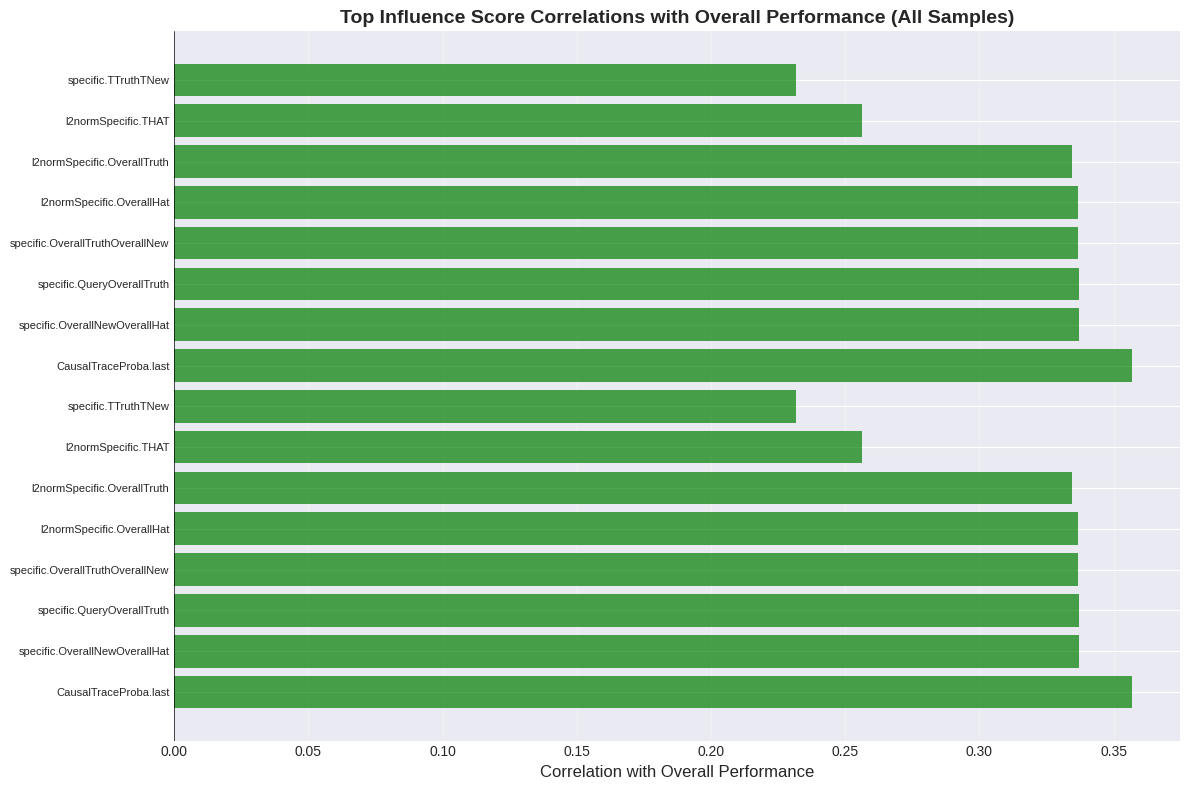


Saved: influence_analysis_results/top_correlations.png


In [50]:
# Plot top 10 positive and negative correlations for Overall metric
overall_col = 'Overall (All)'

if overall_col in df_correlations.columns:
    # Sort by correlation
    df_sorted = df_correlations.sort_values(overall_col, ascending=False)
    
    # Get top 10 positive and bottom 10 (most negative)
    top_10 = df_sorted.head(10)
    bottom_10 = df_sorted.tail(10)
    
    # Combine
    df_plot = pd.concat([top_10, bottom_10])
    
    # Create plot
    fig, ax = plt.subplots(figsize=(12, 8))
    
    y_pos = np.arange(len(df_plot))
    colors = ['green' if x > 0 else 'red' for x in df_plot[overall_col]]
    
    ax.barh(y_pos, df_plot[overall_col], color=colors, alpha=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([t[:50] for t in df_plot['Influence Type']], fontsize=8)
    ax.set_xlabel('Correlation with Overall Performance', fontsize=12)
    ax.set_title('Top Influence Score Correlations with Overall Performance (All Samples)', 
                fontsize=14, fontweight='bold')
    ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    ax.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.savefig(output_dir / 'top_correlations.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\nSaved: {output_dir / 'top_correlations.png'}")

## Analysis Complete

This notebook has:
1. ✓ Loaded influence scores from TracInInf files (one at a time for memory efficiency)
2. ✓ Handled special cases:
   - HiddenStates files with 49 layers (stripped embedding layer)
   - CausalTraceProba.last format (list of tensors)
3. ✓ Computed correlations with performance metrics (proxy, test, all samples)
4. ✓ Identified best layers selected by each influence score type (min and max)
5. ✓ Compared with golden layers from performance analysis
6. ✓ Saved results to CSV files

In [51]:
# Create comprehensive top correlations table with performance metrics
overall_col = 'Overall (All)'

# Sort by correlation
df_sorted = df_correlations.sort_values(overall_col, ascending=False)

# Get top 5 positive and top 5 (or fewer) negative
n_top = 19
top_positive = df_sorted.head(n_top)

# For negative, check how many negatives exist
negative_df = df_sorted[df_sorted[overall_col] < 0]
n_neg = min(n_top, len(negative_df))
top_negative = negative_df.tail(n_neg)  # Most negative

# Combine
df_top_combined = pd.concat([top_positive, top_negative])

# Create summary table
summary_rows = []

for idx, row in df_top_combined.iterrows():
    inf_type = row['Influence Type']
    
    # Convert name
    readable_name = inf_type
    
    # Get correlations
    corr_all = row.get('Overall (All)', np.nan)
    corr_proxy = row.get('Overall (Proxy)', np.nan)
    corr_test = row.get('Overall (Test)', np.nan)
    
    # Find corresponding best layers
    best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
    
    if not best_layer_row.empty:
        # Determine which to use: max or min based on correlation sign
        if "causaltraceproba" in inf_type.lower():
            # Positive correlation: higher score is better, use max
            layers_all = best_layer_row['Max Layer (All)'].values[0]
            layers_proxy = best_layer_row['Max Layer (Proxy)'].values[0]
            layers_test = best_layer_row['Max Layer (Test)'].values[0]
            selection_mode = 'Max'
        else:
            # Negative correlation: lower score is better, use min
            layers_all = best_layer_row['Min Layer (All)'].values[0]
            layers_proxy = best_layer_row['Min Layer (Proxy)'].values[0]
            layers_test = best_layer_row['Min Layer (Test)'].values[0]
            selection_mode = 'Min'
    else:
        layers_all = 'N/A'
        layers_proxy = 'N/A'
        layers_test = 'N/A'
        selection_mode = 'N/A'
    
    # Get performance at the selected layer for ALL 5 metrics
    # This shows how the selected layer (TEST SET) performs on each metric
    perf_metrics = {}
    
    if layers_test != 'N/A':
        try:
            layer_idx = eval(layers_test)[0]  # Take first layer if multiple
            
            # Get performance for all 5 metrics at this layer for TEST SET
            for metric_key, metric_name in analyzer.metrics_info:
                test_means = analyzer.test_means[metric_key]
                perf_value = test_means[layer_idx].item()
                
                # Use short names for columns
                if metric_name == 'Rewrite Accuracy':
                    perf_metrics['Rewrite'] = f"{perf_value:.4f}"
                elif metric_name == 'Rephrase Accuracy':
                    perf_metrics['Rephrase'] = f"{perf_value:.4f}"
                elif metric_name == 'Locality':
                    perf_metrics['Locality'] = f"{perf_value:.4f}"
                elif metric_name == 'Portability':
                    perf_metrics['Portability'] = f"{perf_value:.4f}"
                elif metric_name == 'Overall':
                    perf_metrics['Overall'] = f"{perf_value:.4f}"
        except Exception as e:
            # If any error, set all to N/A
            for name in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']:
                perf_metrics[name] = 'N/A'
    else:
        for name in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']:
            perf_metrics[name] = 'N/A'
    
    summary_rows.append({
        'Method': readable_name,
        'Mode': selection_mode,
        'Corr (All)': f"{corr_all:.4f}",
        'Corr (Proxy)': f"{corr_proxy:.4f}",
        'Corr (Test)': f"{corr_test:.4f}",
        'Layer (All)': layers_all,
        'Layer (Proxy)': layers_proxy,
        'Layer (Test)': layers_test,
        'Rewrite': perf_metrics.get('Rewrite', 'N/A'),
        'Rephrase': perf_metrics.get('Rephrase', 'N/A'),
        'Locality': perf_metrics.get('Locality', 'N/A'),
        'Portability': perf_metrics.get('Portability', 'N/A'),
        'Overall_Perf': perf_metrics.get('Overall', 'N/A')
    })

df_summary_top = pd.DataFrame(summary_rows)

print("="*200)
print("TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE")
print("="*200)
print(f"\nTop {len(top_positive)} Positive and Top {n_neg} Negative correlations")
print("Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance")
print("\nPerformance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):")
print("  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics")
print("  This lets you see how the layer performs across all metrics on the test set")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 200)
print(df_summary_top.to_string(index=False))

# Save to CSV
df_summary_top.to_csv(output_dir / 'top_correlations_summary.csv', index=False)
print(f"\n\nSaved: {output_dir / 'top_correlations_summary.csv'}")

TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE

Top 8 Positive and Top 0 Negative correlations
Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance

Performance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):
  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics
  This lets you see how the layer performs across all metrics on the test set


                         Method Mode Corr (All) Corr (Proxy) Corr (Test) Layer (All) Layer (Proxy) Layer (Test) Rewrite Rephrase Locality Portability Overall_Perf
          CausalTraceProba.last  Max     0.3569       0.3428      0.3588         [6]        [7, 9]          [6]  0.9984   0.8023   0.8960      0.5340       0.8253
  specific.OverallNewOverallHat  Min     0.3372       0.3097      0.3400         [4]           [3]          [4]  0.9995   0.7976   0.9123      0.5381       0.8341
     specific.QueryOverallTruth  Min     0.3371     

In [52]:
# Function to convert influence names to readable format
def convert_influence_to_readable(internal_name):
    target_map = {
        'OverallNew': 'overall_new',
        'OverallOrig': 'overall_hat',
        'OverallHat': 'overall_hat',
        'OverallTruth': 'overall_truth',
        'THAT': 'y_hat',
        'TNew': 'y_new',
        'TTruth': 'y_truth',
        'Query': 'Query'
    }
    
    # Handle CausalTraceProba
    if 'CausalTraceProba' in internal_name:
        return 'CMA (last subject token)'

    # Handle l2normSpecific
    if internal_name.startswith('l2normSpecific.'):
        remainder = internal_name[len('l2normSpecific.'):]
        mapped = target_map.get(remainder, remainder.lower())
        return f'L2-Norm ({mapped})'

    # Handle specific
    if internal_name.startswith('specific.'):
        remainder = internal_name[len('specific.'):]
        
        # Try to extract known target_map keys
        parts = []
        i = 0
        while i < len(remainder):
            for key in sorted(target_map.keys(), key=lambda x: -len(x)):
                if remainder.startswith(key, i):
                    parts.append(target_map[key])
                    i += len(key)
                    break
            else:
                # fallback: take one char to avoid infinite loop
                parts.append(remainder[i].lower())
                i += 1

        if len(parts) >= 2:
            return f'Inf ({parts[0]} & {parts[1]})'
        elif len(parts) == 1:
            return f'Inf ({parts[0]})'
        else:
            return internal_name

    return internal_name

def build_top_correlation_summary(
    df_correlations,
    df_best_layers,
    analyzer,
    n_top=19,
    overall_col='Overall (All)'
):
    # Sort by correlation
    df_sorted = df_correlations.sort_values(overall_col, ascending=False)

    # Select top positive + top negative
    top_positive = df_sorted.head(n_top)
    negative_df = df_sorted[df_sorted[overall_col] < 0]
    top_negative = negative_df.tail(min(n_top, len(negative_df)))

    df_top = pd.concat([top_positive, top_negative])

    summary_rows = []

    for _, row in df_top.iterrows():
        inf_type = row['Influence Type']

        corr_all   = row.get('Overall (All)', np.nan)
        corr_proxy = row.get('Overall (Proxy)', np.nan)
        corr_test  = row.get('Overall (Test)', np.nan)

        best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]

        if not best_layer_row.empty:
            use_max = "causaltraceproba" in inf_type.lower()
            selection_mode = 'Max' if use_max else 'Min'

            layers_all   = best_layer_row['Max Layer (All)'   if use_max else 'Min Layer (All)'].values[0]
            layers_proxy = best_layer_row['Max Layer (Proxy)' if use_max else 'Min Layer (Proxy)'].values[0]
            layers_test  = best_layer_row['Max Layer (Test)'  if use_max else 'Min Layer (Test)'].values[0]
        else:
            layers_all = layers_proxy = layers_test = 'N/A'
            selection_mode = 'N/A'

        # Collect TEST-set performance at selected layer
        perf = {k: 'N/A' for k in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']}

        if layers_test != 'N/A':
            try:
                layer_idx = eval(layers_test)[0]
                for metric_key, metric_name in analyzer.metrics_info:
                    val = analyzer.test_means[metric_key][layer_idx].item()

                    name_map = {
                        'Rewrite Accuracy': 'Rewrite',
                        'Rephrase Accuracy': 'Rephrase',
                        'Locality': 'Locality',
                        'Portability': 'Portability',
                        'Overall': 'Overall'
                    }
                    if metric_name in name_map:
                        perf[name_map[metric_name]] = f"{val:.4f}"
            except Exception:
                pass

        summary_rows.append({
            'Method': inf_type,
            'Readable_Name': convert_influence_to_readable(inf_type),
            'Mode': selection_mode,
            'Corr (All)': f"{corr_all:.4f}",
            'Corr (Proxy)': f"{corr_proxy:.4f}",
            'Corr (Test)': f"{corr_test:.4f}",
            'Layer (All)': layers_all,
            'Layer (Proxy)': layers_proxy,
            'Layer (Test)': layers_test,
            **perf
        })

    return pd.DataFrame(summary_rows)


df_summary_top = pd.DataFrame(summary_rows)

print("="*200)
print("TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE")
print("="*200)
print(f"\nTop {len(top_positive)} Positive and Top {n_neg} Negative correlations")
print("Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance")
print("\nPerformance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):")
print("  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics")
print("  This lets you see how the layer performs across all metrics on the test set")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 200)
print(df_summary_top.to_string(index=False))

# Save to CSV
df_summary_top.to_csv(output_dir / 'top_correlations_summary.csv', index=False)
print(f"\n\nSaved: {output_dir / 'top_correlations_summary.csv'}")

TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE

Top 8 Positive and Top 0 Negative correlations
Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance

Performance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):
  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics
  This lets you see how the layer performs across all metrics on the test set


                         Method Mode Corr (All) Corr (Proxy) Corr (Test) Layer (All) Layer (Proxy) Layer (Test) Rewrite Rephrase Locality Portability Overall_Perf
          CausalTraceProba.last  Max     0.3569       0.3428      0.3588         [6]        [7, 9]          [6]  0.9984   0.8023   0.8960      0.5340       0.8253
  specific.OverallNewOverallHat  Min     0.3372       0.3097      0.3400         [4]           [3]          [4]  0.9995   0.7976   0.9123      0.5381       0.8341
     specific.QueryOverallTruth  Min     0.3371     

## 12. Top Positive and Negative Correlations Summary

This section presents the top 5 positive and top 5 negative correlations with the Overall performance metric, including:
- Readable method names (following the naming convention from the results table)
- Correlation values for All, Proxy, and Test sets
- Best layers selected for All, Proxy, and Test sets

In [53]:
# Create comprehensive top correlations table with performance metrics
overall_col = 'Overall (All)'

# Sort by correlation
df_sorted = df_correlations.sort_values(overall_col, ascending=False)

# Get top 5 positive and top 5 (or fewer) negative
n_top = 19
top_positive = df_sorted.head(n_top)

# For negative, check how many negatives exist
negative_df = df_sorted[df_sorted[overall_col] < 0]
n_neg = min(n_top, len(negative_df))
top_negative = negative_df.tail(n_neg)  # Most negative

# Combine
df_top_combined = pd.concat([top_positive, top_negative])

# First, get the baseline performance from CausalTraceProba.last
baseline_overall_perf = None
for idx, row in df_top_combined.iterrows():
    if row['Influence Type'] == 'CausalTraceProba.last':
        inf_type = row['Influence Type']
        corr_all = row.get('Overall (All)', np.nan)
        
        best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
        if not best_layer_row.empty:
            if corr_all > 0:
                layers_test = best_layer_row['Max Layer (Test)'].values[0]
            else:
                layers_test = best_layer_row['Min Layer (Test)'].values[0]
            
            if layers_test != 'N/A':
                try:
                    layer_idx = eval(layers_test)[0]
                    test_means = analyzer.test_means['post_overall']
                    baseline_overall_perf = test_means[layer_idx].item()
                except:
                    pass
        break

print(f"Baseline CausalTraceProba.last Overall Performance (Test Set): {baseline_overall_perf:.4f}\n")

# Create summary table
summary_rows = []

for idx, row in df_top_combined.iterrows():
    inf_type = row['Influence Type']
    
    # Get correlations
    corr_all = row.get('Overall (All)', np.nan)
    corr_proxy = row.get('Overall (Proxy)', np.nan)
    corr_test = row.get('Overall (Test)', np.nan)
    
    # Find corresponding best layers
    best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
    
    if not best_layer_row.empty:
        # Determine which to use: max or min based on correlation sign
        if "causaltraceproba" in inf_type.lower():
            # Positive correlation: higher score is better, use max
            layers_all = best_layer_row['Max Layer (All)'].values[0]
            layers_proxy = best_layer_row['Max Layer (Proxy)'].values[0]
            layers_test = best_layer_row['Max Layer (Test)'].values[0]
            selection_mode = 'Max'
        else:
            # Negative correlation: lower score is better, use min
            layers_all = best_layer_row['Max Layer (All)'].values[0]
            layers_proxy = best_layer_row['Max Layer (Proxy)'].values[0]
            layers_test = best_layer_row['Max Layer (Test)'].values[0]
            selection_mode = 'Max'
    else:
        layers_all = 'N/A'
        layers_proxy = 'N/A'
        layers_test = 'N/A'
        selection_mode = 'N/A'
    
    # Get performance at the selected layer for ALL 5 metrics
    # This shows how the selected layer (TEST SET) performs on each metric
    perf_metrics = {}
    current_overall_perf = None
    
    if layers_test != 'N/A':
        try:
            layer_idx = eval(layers_test)[0]  # Take first layer if multiple
            
            # Get performance for all 5 metrics at this layer for TEST SET
            for metric_key, metric_name in analyzer.metrics_info:
                test_means = analyzer.test_means[metric_key]
                perf_value = test_means[layer_idx].item()
                
                # Store current overall performance for comparison
                if metric_name == 'Overall':
                    current_overall_perf = perf_value
                
                # Use short names for columns
                if metric_name == 'Rewrite Accuracy':
                    perf_metrics['Rewrite'] = f"{perf_value:.4f}"
                elif metric_name == 'Rephrase Accuracy':
                    perf_metrics['Rephrase'] = f"{perf_value:.4f}"
                elif metric_name == 'Locality':
                    perf_metrics['Locality'] = f"{perf_value:.4f}"
                elif metric_name == 'Portability':
                    perf_metrics['Portability'] = f"{perf_value:.4f}"
                elif metric_name == 'Overall':
                    perf_metrics['Overall'] = f"{perf_value:.4f}"
        except Exception as e:
            # If any error, set all to N/A
            for name in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']:
                perf_metrics[name] = 'N/A'
    else:
        for name in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']:
            perf_metrics[name] = 'N/A'
    
    # Only add readable name if overall performance is better than baseline
    # or if this IS the baseline
    readable_name = inf_type
    
    
    if True: #current_overall_perf >= baseline_overall_perf:
        summary_rows.append({
            'Method': readable_name,
            "Mode": selection_mode,
            'Rewrite': perf_metrics.get('Rewrite', 'N/A'),
            'Rephrase': perf_metrics.get('Rephrase', 'N/A'),
            'Locality': perf_metrics.get('Locality', 'N/A'),
            'Portability': perf_metrics.get('Portability', 'N/A'),
            'Overall_Perf': perf_metrics.get('Overall', 'N/A')
        })

df_summary_top = pd.DataFrame(summary_rows)

print("="*200)
print("TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE")
print("="*200)
print(f"\nTop {len(top_positive)} Positive and Top {n_neg} Negative correlations")
print(f"Baseline: CausalTraceProba.last (Overall: {baseline_overall_perf:.4f})")
print("\nNote: Readable names shown only for methods with Overall performance > baseline")
print("Performance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):")
print("  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 200)
print(df_summary_top.to_string(index=False))

# Save to CSV
df_summary_top.to_csv(output_dir / 'top_correlations_summary.csv', index=False)
print(f"\n\nSaved: {output_dir / 'top_correlations_summary.csv'}")

Baseline CausalTraceProba.last Overall Performance (Test Set): 0.8253

TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE

Top 8 Positive and Top 0 Negative correlations
Baseline: CausalTraceProba.last (Overall: 0.8253)

Note: Readable names shown only for methods with Overall performance > baseline
Performance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):
  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics


                         Method Mode Rewrite Rephrase Locality Portability Overall_Perf
          CausalTraceProba.last  Max  0.9984   0.8023   0.8960      0.5340       0.8253
  specific.OverallNewOverallHat  Max  0.9979   0.7845   0.9017      0.5433       0.8281
     specific.QueryOverallTruth  Max  0.9979   0.7845   0.9017      0.5433       0.8281
specific.OverallTruthOverallNew  Max  0.9979   0.7845   0.9017      0.5433       0.8281
      l2normSpecific.OverallHat  Max  0.9979   0.7845   0.9017      0.5433       0.82

In [54]:
# Function to convert influence names to readable format
def convert_influence_to_readable(internal_name):
    target_map = {
        'OverallNew': 'overall_new',
        'OverallOrig': 'overall_hat',
        'OverallHat': 'overall_hat',
        'OverallTruth': 'overall_truth',
        'THAT': 'y_hat',
        'TNew': 'y_new',
        'TTruth': 'y_truth',
        'Query': 'Query'
    }
    
    # Handle CausalTraceProba
    if 'CausalTraceProba' in internal_name:
        return 'CMA (last subject token)'

    # Handle l2normSpecific
    if internal_name.startswith('l2normSpecific.'):
        remainder = internal_name[len('l2normSpecific.'):]
        mapped = target_map.get(remainder, remainder.lower())
        return f'L2-Norm ({mapped})'

    # Handle specific
    if internal_name.startswith('specific.'):
        remainder = internal_name[len('specific.'):]
        
        # Try to extract known target_map keys
        parts = []
        i = 0
        while i < len(remainder):
            for key in sorted(target_map.keys(), key=lambda x: -len(x)):
                if remainder.startswith(key, i):
                    parts.append(target_map[key])
                    i += len(key)
                    break
            else:
                # fallback: take one char to avoid infinite loop
                parts.append(remainder[i].lower())
                i += 1

        if len(parts) >= 2:
            return f'Inf ({parts[0]} & {parts[1]})'
        elif len(parts) == 1:
            return f'Inf ({parts[0]})'
        else:
            return internal_name

    return internal_name

def build_top_correlation_summary(
    df_correlations,
    df_best_layers,
    analyzer,
    n_top=19,
    overall_col='Overall (All)'
):
    # Sort by correlation
    df_sorted = df_correlations.sort_values(overall_col, ascending=False)

    # Select top positive + top negative
    top_positive = df_sorted.head(n_top)
    negative_df = df_sorted[df_sorted[overall_col] < 0]
    top_negative = negative_df.tail(min(n_top, len(negative_df)))

    df_top = pd.concat([top_positive, top_negative])

    summary_rows = []

    for _, row in df_top.iterrows():
        inf_type = row['Influence Type']

        corr_all   = row.get('Overall (All)', np.nan)
        corr_proxy = row.get('Overall (Proxy)', np.nan)
        corr_test  = row.get('Overall (Test)', np.nan)

        best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]

        if not best_layer_row.empty:
            use_max = "causaltraceproba" in inf_type.lower()
            selection_mode = 'Max' if use_max else 'Min'

            layers_all   = best_layer_row['Max Layer (All)'   if use_max else 'Min Layer (All)'].values[0]
            layers_proxy = best_layer_row['Max Layer (Proxy)' if use_max else 'Min Layer (Proxy)'].values[0]
            layers_test  = best_layer_row['Max Layer (Test)'  if use_max else 'Min Layer (Test)'].values[0]
        else:
            layers_all = layers_proxy = layers_test = 'N/A'
            selection_mode = 'N/A'

        # Collect TEST-set performance at selected layer
        perf = {k: 'N/A' for k in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']}

        if layers_test != 'N/A':
            try:
                layer_idx = eval(layers_proxy)[0]
                for metric_key, metric_name in analyzer.metrics_info:
                    val = analyzer.test_means[metric_key][layer_idx].item()

                    name_map = {
                        'Rewrite Accuracy': 'Rewrite',
                        'Rephrase Accuracy': 'Rephrase',
                        'Locality': 'Locality',
                        'Portability': 'Portability',
                        'Overall': 'Overall'
                    }
                    if metric_name in name_map:
                        perf[name_map[metric_name]] = f"{val:.4f}"
            except Exception:
                pass

        summary_rows.append({
            # 'Method': inf_type,
            'Readable_Name': convert_influence_to_readable(inf_type),
            'Mode': selection_mode,
            # 'Corr (All)': f"{corr_all:.4f}",
            # 'Corr (Proxy)': f"{corr_proxy:.4f}",
            # 'Corr (Test)': f"{corr_test:.4f}",
            # 'Layer (All)': layers_all,
            'Layer (Proxy)': layers_proxy,
            # 'Layer (Test)': layers_test,
            **perf
        })

    return pd.DataFrame(summary_rows)

df_summary_top = pd.DataFrame(build_top_correlation_summary(df_correlations=df_correlations, df_best_layers=df_best_layers, analyzer=analyzer))

print("="*200)
print("TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE")
print("="*200)
print(f"\nTop {len(top_positive)} Positive and Top {n_neg} Negative correlations")
print("Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance")
print("\nPerformance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):")
print("  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics")
print("  This lets you see how the layer performs across all metrics on the test set")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 200)
print(df_summary_top.to_string(index=False))

# Save to CSV
df_summary_top.to_csv(output_dir / 'top_correlations_summary.csv', index=False)
print(f"\n\nSaved: {output_dir / 'top_correlations_summary.csv'}")

TOP POSITIVE AND NEGATIVE CORRELATIONS WITH OVERALL PERFORMANCE

Top 8 Positive and Top 0 Negative correlations
Mode: Max = Higher influence score → Better performance | Min = Lower influence score → Better performance

Performance columns (Rewrite, Rephrase, Locality, Portability, Overall_Perf):
  Show the actual performance at the selected layer (TEST SET) for ALL 5 metrics
  This lets you see how the layer performs across all metrics on the test set


                    Readable_Name Mode Layer (Proxy) Rewrite Rephrase Locality Portability Overall
         CMA (last subject token)  Max        [7, 9]  0.9973   0.8025   0.8763      0.5314  0.8153
  Inf (overall_new & overall_hat)  Min           [3]  0.9986   0.7886   0.9670      0.5476  0.8600
      Inf (Query & overall_truth)  Min           [4]  0.9995   0.7976   0.9123      0.5381  0.8341
Inf (overall_truth & overall_new)  Min          [16]  0.9973   0.7942   0.8693      0.5251  0.8082
            L2-Norm (overall_hat)  Min        

## 13. Proxy-Based Layer Selection with Layer 17 Comparison

This section uses the PROXY set's best layer to evaluate performance on the TEST set.
Additionally shows performance at layer 17 for comparison.

In [58]:
# Create table with proxy-based layer selection and layer 17 performance
overall_col = 'Overall (All)'

# Sort by correlation
df_sorted = df_correlations.sort_values(overall_col, ascending=False)

# Get top 19 positive and negatives
n_top = 19
top_positive = df_sorted.head(n_top)

# For negative, check how many negatives exist
negative_df = df_sorted[df_sorted[overall_col] < 0]
n_neg = min(n_top, len(negative_df))
top_negative = negative_df.tail(n_neg)  # Most negative

# Combine
df_top_combined = pd.concat([top_positive, top_negative])

# First, get the baseline performance from CausalTraceProba.last
baseline_overall_perf = None
for idx, row in df_top_combined.iterrows():
    if row['Influence Type'] == 'CausalTraceProba.last':
        inf_type = row['Influence Type']
        
        best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
        if not best_layer_row.empty:
            layers_test = best_layer_row['Max Layer (Proxy)'].values[0]
            
            if layers_test != 'N/A':
                try:
                    layer_idx = eval(layers_test)[0]
                    test_means = analyzer.test_means['post_overall']
                    baseline_overall_perf = test_means[layer_idx].item()
                except:
                    pass
        break

print(f"Baseline CausalTraceProba.last Overall Performance (Test Set): {baseline_overall_perf:.4f}\n")

# Create summary table with proxy-based selection and layer 17
summary_rows = []

for idx, row in df_top_combined.iterrows():
    inf_type = row['Influence Type']
    
    # Find corresponding best layers
    best_layer_row = df_best_layers[df_best_layers['Influence Type'] == inf_type]
    
    if not best_layer_row.empty:
        
        # Determine selection mode for display
        if 'CausalTraceProba' in inf_type:
            selection_mode = 'Max'
        else:
            selection_mode = 'Min'

        layers_all = best_layer_row[f'{selection_mode} Layer (All)'].values[0]
        layers_proxy = best_layer_row[f'{selection_mode} Layer (Proxy)'].values[0]
        
        # USE PROXY'S BEST LAYER for test set selection
        layers_test_from_proxy = layers_proxy
    else:
        layers_all = 'N/A'
        layers_proxy = 'N/A'
        layers_test_from_proxy = 'N/A'
        selection_mode = 'N/A'
    
    # Get performance at PROXY-SELECTED layer on TEST SET
    perf_metrics_proxy_layer = {}
    current_overall_perf = None
    
    if layers_test_from_proxy != 'N/A':
        try:
            layer_idx = eval(layers_test_from_proxy)[0]  # Take first layer if multiple
            
            # Get performance for all metrics at this layer for TEST SET
            for metric_key, metric_name in analyzer.metrics_info:
                test_means = analyzer.test_means[metric_key]
                perf_value = test_means[layer_idx].item()
                
                # Store current overall performance for comparison
                if metric_name == 'Overall':
                    current_overall_perf = perf_value
                
                # Use short names for columns
                if metric_name == 'Rewrite Accuracy':
                    perf_metrics_proxy_layer['Rewrite'] = f"{perf_value:.4f}"
                elif metric_name == 'Rephrase Accuracy':
                    perf_metrics_proxy_layer['Rephrase'] = f"{perf_value:.4f}"
                elif metric_name == 'Locality':
                    perf_metrics_proxy_layer['Locality'] = f"{perf_value:.4f}"
                elif metric_name == 'Portability':
                    perf_metrics_proxy_layer['Portability'] = f"{perf_value:.4f}"
                elif metric_name == 'Overall':
                    perf_metrics_proxy_layer['Overall'] = f"{perf_value:.4f}"
        except Exception as e:
            for name in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']:
                perf_metrics_proxy_layer[name] = 'N/A'
    else:
        for name in ['Rewrite', 'Rephrase', 'Locality', 'Portability', 'Overall']:
            perf_metrics_proxy_layer[name] = 'N/A'
    
    # Get performance at LAYER 17 on TEST SET
    perf_metrics_layer17 = {}
    layer17_overall_perf = None
    
    try:
        layer_idx = 17
        
        # Get performance for all metrics at layer 17 for TEST SET
        for metric_key, metric_name in analyzer.metrics_info:
            test_means = analyzer.test_means[metric_key]
            perf_value = test_means[layer_idx].item()
            
            # Store layer 17 overall performance
            if metric_name == 'Overall':
                layer17_overall_perf = perf_value
            
            # Use short names for columns
            if metric_name == 'Rewrite Accuracy':
                perf_metrics_layer17['Rewrite_L17'] = f"{perf_value:.4f}"
            elif metric_name == 'Rephrase Accuracy':
                perf_metrics_layer17['Rephrase_L17'] = f"{perf_value:.4f}"
            elif metric_name == 'Locality':
                perf_metrics_layer17['Locality_L17'] = f"{perf_value:.4f}"
            elif metric_name == 'Portability':
                perf_metrics_layer17['Portability_L17'] = f"{perf_value:.4f}"
            elif metric_name == 'Overall':
                perf_metrics_layer17['Overall_L17'] = f"{perf_value:.4f}"
    except Exception as e:
        for name in ['Rewrite_L17', 'Rephrase_L17', 'Locality_L17', 'Portability_L17', 'Overall_L17']:
            perf_metrics_layer17[name] = 'N/A'
    
    # Only add if overall performance is better than or equal to baseline
    if current_overall_perf is not None and True: #current_overall_perf >= baseline_overall_perf:
        summary_rows.append({
            'Method': inf_type,
            'Mode': selection_mode,
            'Layer (Proxy)': layers_proxy,
            'Rewrite': perf_metrics_proxy_layer.get('Rewrite', 'N/A'),
            'Rephrase': perf_metrics_proxy_layer.get('Rephrase', 'N/A'),
            'Locality': perf_metrics_proxy_layer.get('Locality', 'N/A'),
            'Portability': perf_metrics_proxy_layer.get('Portability', 'N/A'),
            'Overall': perf_metrics_proxy_layer.get('Overall', 'N/A'),
            'Rewrite_L17': perf_metrics_layer17.get('Rewrite_L17', 'N/A'),
            'Rephrase_L17': perf_metrics_layer17.get('Rephrase_L17', 'N/A'),
            'Locality_L17': perf_metrics_layer17.get('Locality_L17', 'N/A'),
            'Portability_L17': perf_metrics_layer17.get('Portability_L17', 'N/A'),
            'Overall_L17': perf_metrics_layer17.get('Overall_L17', 'N/A')
        })

df_summary_proxy = pd.DataFrame(summary_rows)

print("="*250)
print("METHODS WITH PERFORMANCE >= BASELINE (USING PROXY-SELECTED LAYER ON TEST SET)")
print("="*250)
print(f"\nBaseline: CausalTraceProba.last (Overall: {baseline_overall_perf:.4f})")
print("\nLayer Selection: Test set evaluated at the layer selected by PROXY set")
print("Performance columns (Rewrite, Rephrase, Locality, Portability, Overall): Performance at proxy-selected layer")
print("Performance columns with _L17 suffix: Performance at layer 17 (for comparison)")
print("\n")

# Display with nice formatting
pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 250)
print("Model: LLAMA2, Dataset: Counteract")
print(df_summary_proxy.to_string(index=False))

# Save to CSV
df_summary_proxy.to_csv(output_dir / 'methods_proxy_selection_with_layer17.csv', index=False)
print(f"\n\nSaved: {output_dir / 'methods_proxy_selection_with_layer17.csv'}")

Baseline CausalTraceProba.last Overall Performance (Test Set): 0.8153

METHODS WITH PERFORMANCE >= BASELINE (USING PROXY-SELECTED LAYER ON TEST SET)

Baseline: CausalTraceProba.last (Overall: 0.8153)

Layer Selection: Test set evaluated at the layer selected by PROXY set
Performance columns (Rewrite, Rephrase, Locality, Portability, Overall): Performance at proxy-selected layer
Performance columns with _L17 suffix: Performance at layer 17 (for comparison)


Model: LLAMA2, Dataset: Counteract
                         Method Mode Layer (Proxy) Rewrite Rephrase Locality Portability Overall Rewrite_L17 Rephrase_L17 Locality_L17 Portability_L17 Overall_L17
          CausalTraceProba.last  Max        [7, 9]  0.9973   0.8025   0.8763      0.5314  0.8153      0.9953       0.7802       0.8669          0.5149      0.7977
  specific.OverallNewOverallHat  Min           [3]  0.9986   0.7886   0.9670      0.5476  0.8600      0.9953       0.7802       0.8669          0.5149      0.7977
     specific.

In [56]:
# Function to convert influence names to readable format
def convert_influence_to_readable(internal_name):
    """
    Convert internal influence type names to readable format.
    
    Examples:
    - CausalTraceProba.last -> CMA (last subject token)
    - specific.TNewTTruth -> Inf (y_new & y_truth)
    - l2normSpecific.Query -> L2-Norm (Query)
    """
    # Handle CausalTraceProba
    if 'CausalTraceProba' in internal_name:
        return 'CMA (last subject token)'
    
    # Mapping for target types
    target_map = {
        'OverallNew': 'overall_new',
        'OverallOrig': 'overall_hat',
        'OverallHat': 'overall_hat',
        'OverallTruth': 'overall_truth',
        'THAT': 'y_hat',
        'TNew': 'y_new',
        'TTruth': 'y_truth',
        'Query': 'Query'
    }
    
    # Handle l2normSpecific (one part)
    if internal_name.startswith('l2normSpecific.'):
        remainder = internal_name[15:]  # Remove 'l2normSpecific.'
        mapped = target_map.get(remainder, remainder.lower())
        return f'L2-Norm ({mapped})'
    
    # Handle specific (two parts)
    elif internal_name.startswith('specific.'):
        remainder = internal_name[9:]  # Remove 'specific.'
        
        # Split by camelCase to get two parts
        parts = []
        current = ''
        for i, char in enumerate(remainder):
            if char.isupper() and current:
                # Check if this starts a new word
                # Look ahead to see if we have more uppercase (acronym) or lowercase (new word)
                if i + 1 < len(remainder) and remainder[i + 1].islower():
                    parts.append(current)
                    current = char
                else:
                    current += char
            else:
                current += char
        if current:
            parts.append(current)
        
        # Map each part
        mapped_parts = [target_map.get(part, part.lower()) for part in parts]
        
        # Format based on number of parts
        if len(mapped_parts) >= 2:
            return f'Inf ({mapped_parts[0]} & {mapped_parts[1]})'
        elif len(mapped_parts) == 1:
            return f'Inf ({mapped_parts[0]})'
        else:
            return internal_name
    
    return internal_name


def format_with_ranking(df, column, higher_is_better=True):
    """
    Format values in a column with bold for best and underline for second-best.
    
    Args:
        df: DataFrame
        column: Column name to format
        higher_is_better: If True, higher values are better. If False, lower values are better.
    
    Returns:
        Series with formatted values
    """
    # Convert to numeric, handling string values
    values = pd.to_numeric(df[column], errors='coerce')
    
    # Get unique sorted values
    unique_values = sorted(values.dropna().unique(), reverse=higher_is_better)
    
    if len(unique_values) == 0:
        return df[column]
    
    # Get best and second-best values
    best_value = unique_values[0] if len(unique_values) > 0 else None
    second_best_value = unique_values[1] if len(unique_values) > 1 else None
    
    # Format the column
    formatted = []
    for val in df[column]:
        try:
            num_val = float(val)
            if best_value is not None and num_val == best_value:
                formatted.append(f'**{val}**')
            elif second_best_value is not None and num_val == second_best_value:
                formatted.append(f'<u>{val}</u>')
            else:
                formatted.append(str(val))
        except (ValueError, TypeError):
            formatted.append(str(val))
    
    return formatted


# Create markdown table from the dataframe
def create_markdown_table(df):
    """
    Create a formatted markdown table with:
    - CausalTraceProba at the beginning
    - Other methods in the middle
    - Layer 17 as a separate row at the end
    - Bold for best values, underline for second-best
    """
    # Make a copy and add readable names
    df_copy = df.copy()
    df_copy['Readable_Name'] = df_copy['Method'].apply(convert_influence_to_readable)
    
    # Separate CausalTraceProba and others
    causal_rows = df_copy[df_copy['Method'].str.contains('CausalTraceProba')]
    other_rows = df_copy[~df_copy['Method'].str.contains('CausalTraceProba')]
    
    # Sort others by Overall performance (descending)
    other_rows = other_rows.sort_values('Overall', ascending=False)
    
    # Combine: CausalTraceProba first, then others
    df_sorted = pd.concat([causal_rows, other_rows])
    
    # Remove duplicates
    df_sorted = df_sorted.drop_duplicates(subset=['Method'])
    
    # Select columns WITHOUT L17 suffix
    columns_order = [
        'Readable_Name',
        'Mode',
        'Layer (Proxy)',
        'Rewrite',
        'Rephrase',
        'Locality',
        'Portability',
        'Overall'
    ]
    
    df_display = df_sorted[columns_order].copy()
    
    # Rename columns for display
    df_display.columns = [
        'Method',
        'Mode',
        'Layer',
        'Rewrite',
        'Rephrase',
        'Locality',
        'Portability',
        'Overall'
    ]
    
    # Create Layer 17 row (using first row's L17 values since they're all the same)
    if len(df_sorted) > 0:
        first_row = df_sorted.iloc[0]
        layer17_row = pd.DataFrame([{
            'Method': '**Layer 17 (Fixed)**',
            'Mode': '-',
            'Layer': '17',
            'Rewrite': first_row['Rewrite_L17'],
            'Rephrase': first_row['Rephrase_L17'],
            'Locality': first_row['Locality_L17'],
            'Portability': first_row['Portability_L17'],
            'Overall': first_row['Overall_L17']
        }])
        
        # Append Layer 17 row
        df_display = pd.concat([df_display, layer17_row], ignore_index=True)
    
    # Apply formatting to numeric columns (higher is better for all metrics)
    df_display['Rewrite'] = format_with_ranking(df_display, 'Rewrite', higher_is_better=True)
    df_display['Rephrase'] = format_with_ranking(df_display, 'Rephrase', higher_is_better=True)
    df_display['Locality'] = format_with_ranking(df_display, 'Locality', higher_is_better=True)
    df_display['Portability'] = format_with_ranking(df_display, 'Portability', higher_is_better=True)
    df_display['Overall'] = format_with_ranking(df_display, 'Overall', higher_is_better=True)
    
    # Create markdown table
    md_lines = []
    md_lines.append('')
    md_lines.append('## Results: Proxy-Selected Layer Performance')
    md_lines.append('')
    md_lines.append(f'**Baseline**: CMA (last subject token) - Overall performance at its selected layer')
    md_lines.append('')
    md_lines.append('**Note**: All methods show TEST set performance at the layer selected by PROXY set. Layer 17 row shows fixed performance for comparison.')
    md_lines.append('')
    md_lines.append('**Formatting**: **Bold** = Best value, <u>Underline</u> = Second-best value (per column)')
    md_lines.append('')
    
    # Header
    header = '| ' + ' | '.join(df_display.columns) + ' |'
    separator = '|' + '|'.join(['---' for _ in df_display.columns]) + '|'
    
    md_lines.append(header)
    md_lines.append(separator)
    
    # Data rows
    for idx, row in df_display.iterrows():
        row_str = '| ' + ' | '.join(str(val) for val in row) + ' |'
        md_lines.append(row_str)
    
    md_lines.append('')
    
    return '\n'.join(md_lines)


# Generate markdown table
markdown_table = create_markdown_table(df_summary_proxy)

# Print to console
print(markdown_table)

# Save to file
output_path = output_dir / 'proxy_selection_results.md'
with open(output_path, 'w') as f:
    f.write(markdown_table)

print(f"\n\nSaved markdown table to: {output_path}")


## Results: Proxy-Selected Layer Performance

**Baseline**: CMA (last subject token) - Overall performance at its selected layer

**Note**: All methods show TEST set performance at the layer selected by PROXY set. Layer 17 row shows fixed performance for comparison.

**Formatting**: **Bold** = Best value, <u>Underline</u> = Second-best value (per column)

| Method | Mode | Layer | Rewrite | Rephrase | Locality | Portability | Overall |
|---|---|---|---|---|---|---|---|
| CMA (last subject token) | Max | [7, 9] | 0.9973 | **0.8025** | 0.8763 | 0.5314 | 0.8153 |
| Inf (overall & new) | Min | [3] | <u>0.9986</u> | 0.7886 | **0.9670** | **0.5476** | **0.8600** |
| L2-Norm (y_hat) | Min | [3] | <u>0.9986</u> | 0.7886 | **0.9670** | **0.5476** | **0.8600** |
| Inf (Query & overall) | Min | [4] | **0.9995** | <u>0.7976</u> | <u>0.9123</u> | <u>0.5381</u> | <u>0.8341</u> |
| Inf (t & trutht) | Min | [7] | 0.9973 | **0.8025** | 0.8763 | 0.5314 | 0.8153 |
| **Layer 17 (Fixed)** | - | 17 | 0.995